# 06 Annex: will the spread widen by 25 bp?

Naive Bayes only classifies, so the annex asks: will this bond's spread widen by 25 bp or more by next month-end (`widens_25bp`)? Naive Bayes against the other classifiers from the course. Predicting moves is much harder than predicting levels, so a weak result is expected.

Class notebooks followed: `2. Naive_Bayes_SMS` (the structure) and `1_Naive_Bayes_Tweets` (Bayes' theorem, priors, smoothing). Changes for our data: our inputs are numbers, not words, so the Naive Bayes variants are Gaussian NB and Categorical NB on binned features instead of Multinomial NB on word counts; time-ordered folds instead of `StratifiedKFold`.

Validation months only: the test months are scored once, in `99_final`. Runs top to bottom in about 10 minutes on a laptop; figures go to
`reports/figures/06_*.png`.

In [1]:
# Deck style for every figure: IG is always teal, HY always orange
import matplotlib.pyplot as plt

DECK = {"teal": "#114A6B", "orange": "#FF5F00", "slate": "#3A4550", "grey": "#8A949C", "pale": "#DCE6EC"}
plt.rcParams.update({
    "font.family": "Arial", "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": DECK["grey"], "axes.labelcolor": DECK["slate"], "axes.titleweight": "bold",
    "axes.titlecolor": DECK["teal"],
    "axes.prop_cycle": plt.cycler(color=[DECK["teal"], DECK["orange"], DECK["grey"], DECK["slate"]]),
    "xtick.color": DECK["slate"], "ytick.color": DECK["slate"], "axes.grid": True, "axes.grid.axis": "y",
    "axes.axisbelow": True, "grid.color": DECK["pale"],
    "figure.figsize": (10, 5.6), "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})

## 1. Setup

Rows without a next month have no label and are dropped by `xy()`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import xgboost as xgb
except ImportError:
    xgb = None
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, log_loss, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier

from ml2.config import load_config, resolve
from ml2.data import check_panel, load_panel
from ml2.features import categorical_columns, make_preprocessor, numeric_columns, xy
from ml2.splits import walk_forward_folds

cfg = load_config()
TARGET = cfg["problem"]["annex_target"]
PREFIX = "06"
FIG = resolve("reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    """Save a figure to reports/figures/<prefix>_<name>.png."""
    fig.savefig(FIG / f"{PREFIX}_{name}.png", dpi=150, bbox_inches="tight")


check_panel()
df = load_panel(partitions=["train", "valid"])
train, valid = df[df.partition == "train"], df[df.partition == "valid"]
X_tr, y_tr = xy(train, target=TARGET)
X_va, y_va = xy(valid, target=TARGET)
y_tr, y_va = y_tr.astype(int), y_va.astype(int)
cv = walk_forward_folds(train.loc[X_tr.index, "snapshot_date"])  # replaces StratifiedKFold in the class notebook
print(f"train {X_tr.shape}, base rate {y_tr.mean():.3f}; valid {X_va.shape}, base rate {y_va.mean():.3f}")

train (103689, 33), base rate 0.034; valid (24565, 33), base rate 0.021
None


Of 24,565 labelled validation bond-months, 511 widened by at least 25 basis points the following month (2.08%). Predicting no widening every time would achieve 97.92% accuracy and miss every event.

## 2. Reference model

Always predict the training rate. Its log loss is the bar for calibrated probabilities; its AUC is 0.5.

In [3]:
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
results = {}


def evaluate(name, p_va, threshold=None):
    """Valid metrics for predicted probabilities; precision and recall at the chosen threshold."""
    r = {"AUC": roc_auc_score(y_va, p_va), "log loss": log_loss(y_va, p_va)}
    if threshold is not None:
        yhat = (p_va >= threshold).astype(int)
        r.update({"threshold": threshold, "precision": precision_score(y_va, yhat, zero_division=0),
                  "recall": recall_score(y_va, yhat)})
    results[name] = {**r, "p": p_va}
    return pd.Series(r).round(3)


evaluate("Reference (training rate)", dummy.predict_proba(X_va)[:, 1])

AUC         0.500
log loss    0.104
dtype: float64


## 3. Gaussian Naive Bayes

Bayes' theorem: P(widens | features) is proportional to P(widens) x P(features | widens). "Naive": the features are
assumed independent given the class, so P(features | widens) is the product of one term per feature. Gaussian NB
models each numeric feature as a normal distribution within each class, here on scaled features.

In [4]:
gnb = Pipeline([("pre", make_preprocessor()), ("nb", GaussianNB())]).fit(X_tr, y_tr)
evaluate("Gaussian Naive Bayes", gnb.predict_proba(X_va)[:, 1])

AUC          0.692
log loss    28.694
dtype: float64


## 4. Categorical Naive Bayes

Our features are numbers, not words: binned into quintiles, then Categorical NB counts how often each bin occurs
in each class, the role the class's Multinomial NB on word counts played. Laplace smoothing (`alpha=1`) adds one
to every count, so a bin never seen with a 1 does not get probability zero (which would veto the whole product).

In [5]:
def make_binned(num_cols, cat_cols):
    # impute, bin numbers into quintiles, encode categories, and shift the codes by one so an unseen category
    # becomes 0 instead of -1 (Categorical NB needs non-negative integer codes)
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("bin", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile", random_state=42))]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("shift", FunctionTransformer(lambda a: a + 1))]), cat_cols),
    ])


binned = make_binned(numeric_columns(), categorical_columns())
cnb = Pipeline([("pre", binned), ("nb", CategoricalNB(alpha=1.0))]).fit(X_tr, y_tr)
evaluate("Categorical Naive Bayes", cnb.predict_proba(X_va)[:, 1])

AUC         0.735
log loss    0.438
dtype: float64


## 5. Compare the variants

Naive_Bayes_SMS compared bag-of-words with TF-IDF by cross-validated ROC AUC; here Gaussian against Categorical NB, on the time-ordered folds.

In [6]:
pipe = Pipeline([("pre", make_preprocessor()), ("nb", GaussianNB())])
search = GridSearchCV(pipe, [{"pre": [make_preprocessor()], "nb": [GaussianNB()]},
                             {"pre": [binned], "nb": [CategoricalNB(alpha=1.0)]}],
                      scoring="roc_auc", cv=cv, n_jobs=-1, refit=True).fit(X_tr, y_tr)
pd.DataFrame(search.cv_results_)[["param_nb", "mean_test_score", "std_test_score"]].round(3)

          param_nb  mean_test_score  std_test_score
0     GaussianNB()            0.609           0.082
1  CategoricalNB()            0.810           0.038


## 6. Choose the threshold

Naive_Bayes_SMS: the threshold is chosen on out-of-fold predictions of the training data (never on valid), at the
best F1. `cross_val_predict` needs folds that cover every row, which time-ordered folds do not, so the out-of-fold
predictions are collected with a short loop.

threshold 0.453
              precision    recall  f1-score   support

           0      0.987     0.878     0.929     24054
           1      0.071     0.434     0.121       511

    accuracy                          0.869     24565
   macro avg      0.529     0.656     0.525     24565
weighted avg      0.967     0.869     0.913     24565

[[21129  2925]
 [  289   222]]
AUC          0.735
log loss     0.438
threshold    0.453
precision    0.071
recall       0.434
dtype: float64


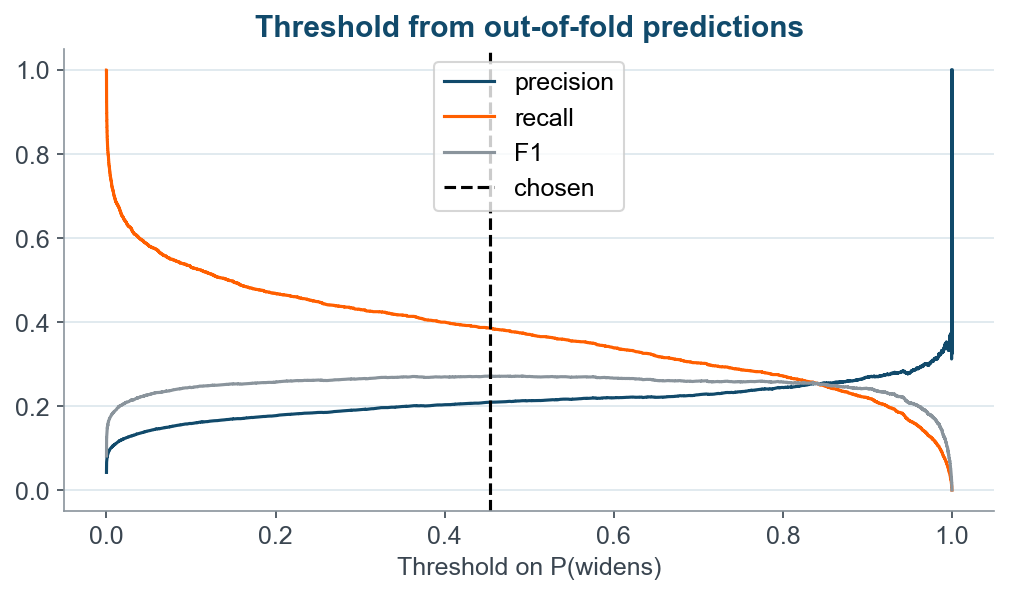

In [7]:
def oof_threshold(model, X=X_tr, y=y_tr, folds=cv):
    """F1-optimal threshold from out-of-fold predictions on the training folds."""
    idx, prob = [], []
    for tr_i, va_i in folds:
        m = clone(model).fit(X.iloc[tr_i], y.iloc[tr_i])
        idx.append(va_i); prob.append(m.predict_proba(X.iloc[va_i])[:, 1])
    idx, prob = np.concatenate(idx), np.concatenate(prob)
    precision, recall, thresholds = precision_recall_curve(y.iloc[idx], prob)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.argmax(f1))]), (precision, recall, thresholds, f1)


best_threshold, (precision, recall, thresholds, f1) = oof_threshold(search.best_estimator_)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, precision[:-1], label="precision"); ax.plot(thresholds, recall[:-1], label="recall")
ax.plot(thresholds, f1, label="F1"); ax.axvline(best_threshold, color="black", ls="--", label="chosen")
ax.set_xlabel("Threshold on P(widens)"); ax.set_title("Threshold from out-of-fold predictions"); ax.legend()
save(fig, "threshold")

p_va = search.best_estimator_.predict_proba(X_va)[:, 1]
print(f"threshold {best_threshold:.3f}")
print(classification_report(y_va, (p_va >= best_threshold).astype(int), digits=3))
print(confusion_matrix(y_va, (p_va >= best_threshold).astype(int)))
# The winning variant's row in the comparison table now carries its threshold, precision and recall
nb_name = "Gaussian Naive Bayes" if isinstance(search.best_estimator_["nb"], GaussianNB) else "Categorical Naive Bayes"
evaluate(nb_name, p_va, best_threshold)

## 7. The independence problem

Highly correlated features (see 01, correlations) are counted as separate evidence, so Naive Bayes becomes
over-confident: probabilities pushed to 0 or 1, which the log loss punishes. Refit Categorical NB keeping one of
each correlated group.

In [8]:
DROP = ["vol_20d", "vol_60d", "mom_12_1", "bbb_oas_bps", "slope_2s10s_bps"]  # keep vol_252d, ret_252d, hy_oas_bps
reduced = [c for c in numeric_columns() if c not in DROP]
cnb_reduced = Pipeline([("pre", make_binned(reduced, categorical_columns())), ("nb", CategoricalNB(alpha=1.0))])
cnb_reduced.fit(X_tr, y_tr)
print("dropped:", DROP)
evaluate("Categorical NB, one per correlated group", cnb_reduced.predict_proba(X_va)[:, 1])

dropped: ['vol_20d', 'vol_60d', 'mom_12_1', 'bbb_oas_bps', 'slope_2s10s_bps']
AUC         0.716
log loss    0.288
dtype: float64


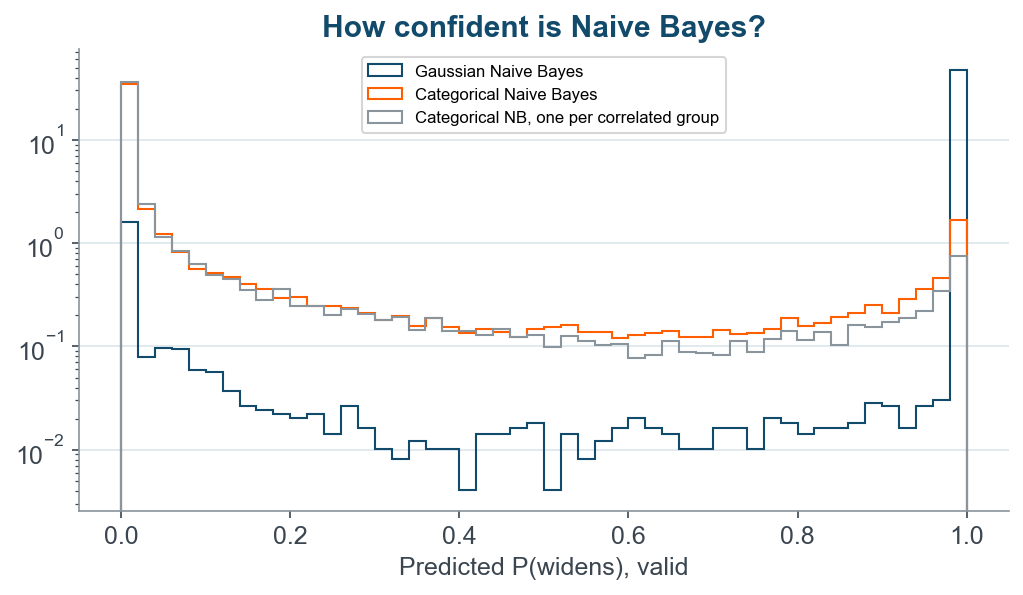

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["Gaussian Naive Bayes", "Categorical Naive Bayes", "Categorical NB, one per correlated group"]:
    ax.hist(results[name]["p"], bins=50, histtype="step", label=name, density=True)
ax.set_yscale("log"); ax.set_xlabel("Predicted P(widens), valid"); ax.set_title("How confident is Naive Bayes?")
ax.legend(fontsize=8)
save(fig, "nb_confidence")

Gaussian Naive Bayes assigned a probability above 99% to 94.5% of validation observations. Removing five correlated features from categorical Naive Bayes lowered log loss from 0.438 to 0.288, while AUC fell from 0.735 to 0.716. Both variants had higher log loss than the training-prevalence baseline (0.104).

## 8. The other classifiers

Same features, folds and threshold method; small grids. KNN is fitted on a 30,000-row sample (prediction is slow
on all rows). Logistic regression is a reference, from ML I (`Logit_for_Classification`).

In [10]:
tree_pre = lambda: make_preprocessor(scale=False, one_hot=False)  # noqa: E731
candidates = {
    "Pruned decision tree": GridSearchCV(
        Pipeline([("pre", tree_pre()), ("est", DecisionTreeClassifier(random_state=42))]),
        {"est__max_depth": [4, 6, 8], "est__min_samples_leaf": [100, 500]}, scoring="roc_auc", cv=cv, n_jobs=-1),
    "Random forest": GridSearchCV(
        Pipeline([("pre", tree_pre()), ("est", RandomForestClassifier(n_estimators=200, random_state=42,
                                                                      n_jobs=-1))]),
        {"est__min_samples_leaf": [20, 100], "est__max_features": ["sqrt", 0.3]}, scoring="roc_auc", cv=cv),
    **({"XGBoost": GridSearchCV(
        Pipeline([("pre", tree_pre()), ("est", xgb.XGBClassifier(n_estimators=300, subsample=0.8,
                                                                 colsample_bytree=0.7, random_state=42, n_jobs=-1))]),
        {"est__max_depth": [3, 6], "est__learning_rate": [0.05, 0.1]}, scoring="roc_auc", cv=cv),
    } if xgb is not None else {}),
    "Logistic regression": GridSearchCV(
        Pipeline([("pre", make_preprocessor()), ("est", LogisticRegression(max_iter=2000))]),
        {"est__C": [0.1, 1.0]}, scoring="roc_auc", cv=cv, n_jobs=-1),
}
fitted = {}
for name, gs in candidates.items():
    gs.fit(X_tr, y_tr)
    model = gs.best_estimator_
    thr, _ = oof_threshold(model)
    fitted[name] = model
    print(name, gs.best_params_, f"CV AUC {gs.best_score_:.3f}")
    display(evaluate(name, model.predict_proba(X_va)[:, 1], thr))

Pruned decision tree {'est__max_depth': 6, 'est__min_samples_leaf': 100} CV AUC 0.798
AUC          0.775
log loss     0.107
threshold    0.085
precision    0.116
recall       0.419
dtype: float64
Random forest {'est__max_features': 'sqrt', 'est__min_samples_leaf': 100} CV AUC 0.823
AUC          0.800
log loss     0.092
threshold    0.076
precision    0.098
recall       0.593
dtype: float64
Logistic regression {'est__C': 0.1} CV AUC 0.739
AUC          0.802
log loss     0.095
threshold    0.009
precision    0.025
recall       0.933
dtype: float64


In [11]:
# KNN on a 30,000-row sample of train (time order kept for its folds)
knn_rows = X_tr.sample(30000, random_state=42).index
X_k, y_k = X_tr.loc[knn_rows].sort_index(), y_tr.loc[knn_rows].sort_index()
cv_k = walk_forward_folds(train.loc[X_k.index, "snapshot_date"])
gs = GridSearchCV(Pipeline([("pre", make_preprocessor()), ("est", KNeighborsClassifier())]),
                  {"est__n_neighbors": [25, 50, 100]}, scoring="roc_auc", cv=cv_k, n_jobs=-1).fit(X_k, y_k)
thr, _ = oof_threshold(gs.best_estimator_, X_k, y_k, cv_k)
fitted["KNN"] = gs.best_estimator_
print("KNN", gs.best_params_, f"CV AUC {gs.best_score_:.3f}")
evaluate("KNN (30,000-row sample)", gs.best_estimator_.predict_proba(X_va)[:, 1], thr)

KNN {'est__n_neighbors': 100} CV AUC 0.710
AUC          0.777
log loss     0.150
threshold    0.030
precision    0.043
recall       0.730
dtype: float64


## 9. Comparison table

Valid, every model. ROC curves in one figure. Thresholds come from the training months, where about 1 bond in 30
widens; in the calmer validation months it is about 1 in 50, so a threshold that was right in training flags too
many bonds on valid. Read precision and recall with that in mind; AUC and log loss do not depend on the threshold.

                                            AUC  log loss  ...  precision  recall
Logistic regression                       0.802     0.095  ...      0.025   0.933
Random forest                             0.800     0.092  ...      0.098   0.593
KNN (30,000-row sample)                   0.777     0.150  ...      0.043   0.730
Pruned decision tree                      0.775     0.107  ...      0.116   0.419
Categorical Naive Bayes                   0.735     0.438  ...      0.071   0.434
Categorical NB, one per correlated group  0.716     0.288  ...        NaN     NaN
Gaussian Naive Bayes                      0.692    28.694  ...        NaN     NaN
Reference (training rate)                 0.500     0.104  ...        NaN     NaN

[8 rows x 5 columns]


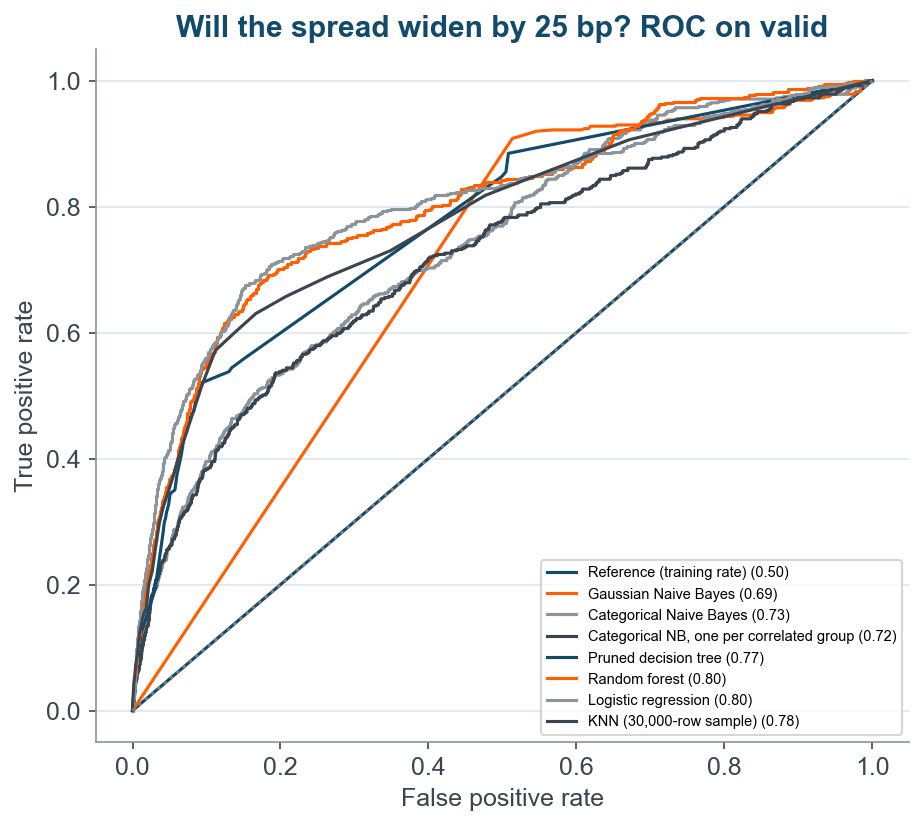

In [12]:
table = pd.DataFrame({k: {m: v for m, v in r.items() if m != "p"} for k, r in results.items()}).T
table = table[["AUC", "log loss", "threshold", "precision", "recall"]].sort_values("AUC", ascending=False)
table.to_csv(FIG.parent / "06_comparison_valid.csv")

fig, ax = plt.subplots(figsize=(7, 6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_va, r["p"])
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_va, r['p']):.2f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Will the spread widen by 25 bp? ROC on valid"); ax.legend(fontsize=7)
save(fig, "roc")
table.round(3)

In [13]:
# Which signals warn that a bond is about to widen? Permutation-free view: the random forest's importances
rf = fitted["Random forest"]
pd.Series(rf["est"].feature_importances_, index=rf["pre"].get_feature_names_out()).sort_values(
    ascending=False).head(10).round(3)

grade_bucket            0.112
hy_oas_bps              0.061
naive_dd                0.060
slope_2s10s_bps         0.058
vix                     0.055
log_market_cap          0.049
bbb_oas_bps             0.044
leverage                0.043
vol_252d                0.042
log_par_volume_month    0.042
dtype: float64


**Validation results on panel d817a09a.** Categorical Naive Bayes had higher mean training-fold AUC than Gaussian Naive Bayes (0.810 versus 0.609). At its training-selected threshold of 0.453, categorical Naive Bayes detected 222 of 511 widening events, missed 289 and generated 2,925 false alerts. That is 43.4% recall and 7.1% precision. The alerts identify a higher-risk subset, but most flagged bonds did not widen by 25 basis points.

Among the completed models, logistic regression had the highest validation AUC (0.802), closely followed by random forest (0.800). Random forest had the lowest log loss (0.092). Grade bucket, high-yield OAS and distance to default ranked highest by forest impurity importance. This ranking does not determine the direction of each relationship. XGBoost was unavailable in this run.

## 10. RUN_LOG

One line per model.

In [14]:
today = pd.Timestamp.today().strftime("%Y-%m-%d")
for name, r in table.iterrows():
    extra = "" if pd.isna(r["threshold"]) else (f", threshold {r['threshold']:.3f}: precision {r['precision']:.2f}, "
                                                f"recall {r['recall']:.2f}")
    features = "all 33"
    if name.startswith("Reference"):
        features = "training prevalence"
    elif name.startswith("Categorical NB, one per"):
        features = "28 predictors"
    print(f"| {today} | Farah Alnuseirat | 06_annex_classification | {name} | {features} | fit on train, scored on valid | "
          f"n/a (AUC {r['AUC']:.3f}, log loss {r['log loss']:.3f}{extra}) | widens_25bp, panel d817a09a |")

| 2026-11-22 | Farah Alnuseirat | 06_annex_classification | Logistic regression | all 33 | fit on train, scored on valid | n/a (AUC 0.802, log loss 0.095, threshold 0.009: precision 0.03, recall 0.93) | widens_25bp, panel d817a09a |
| 2026-11-22 | Farah Alnuseirat | 06_annex_classification | Random forest | all 33 | fit on train, scored on valid | n/a (AUC 0.800, log loss 0.092, threshold 0.076: precision 0.10, recall 0.59) | widens_25bp, panel d817a09a |
| 2026-11-22 | Farah Alnuseirat | 06_annex_classification | KNN (30,000-row sample) | all 33 | fit on train, scored on valid | n/a (AUC 0.777, log loss 0.150, threshold 0.030: precision 0.04, recall 0.73) | widens_25bp, panel d817a09a |
| 2026-11-22 | Farah Alnuseirat | 06_annex_classification | Pruned decision tree | all 33 | fit on train, scored on valid | n/a (AUC 0.775, log loss 0.107, threshold 0.085: precision 0.12, recall 0.42) | widens_25bp, panel d817a09a |
| 2026-11-22 | Farah Alnuseirat | 06_annex_classification | Categoric